# Activity: Can We Trust the AI Analyst? — FreshKart Case

**Unit 4 · AI-Assisted Visualization · LLMs for EDA & Human-in-the-Loop Visualization**
Visualization of Data, Understanding and Interpretation (UE24CS342AA9)

---

## The case

**FreshKart** is a quick-commerce grocery chain with **10 dark stores in 3 cities** (Bengaluru, Pune, Hyderabad). Operations head **Meera** has a leadership meeting tomorrow. She asked an AI analytics assistant:

> *"Summarise our business from January to September and tell me what went wrong in September."*

The assistant has produced the report below. **You are the analyst.** Meera will present whatever you sign off, so your job is to **verify, correct or reject** each AI insight using the data, and to say *why*.

**Ground rules (from the lecture):** every number must come from code you can inspect · an alert tells you where to look, a chart tells you what is true · the AI proposes, the human decides.

**How to work:** run the notebook top to bottom. Complete every cell marked `# TODO` (replace `None` with your code or answer) and write in the cells marked **✏️ Your answer**. Cells that depend on your TODO will tell you if something is still missing.

### The data: `freshkart_orders.csv` (synthetic)

| Column | Meaning |
|---|---|
| `order_id` | unique order reference |
| `order_date` | date of order |
| `city`, `store_id` | where the order was fulfilled |
| `zone` | `Urban` or `Suburban` delivery address |
| `delivery_partner` | `Partner A` or `Partner B` |
| `items`, `discount_pct`, `order_value` | basket size, discount applied, bill value (₹) |
| `distance_km`, `delivery_minutes`, `on_time` | delivery distance, time taken, 1 if ≤ 30 min |
| `rating` | customer rating 1–5 (blank if not given) |
| `app_sessions_7d`, `loyalty_points` | customer app activity and loyalty balance |

In [37]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (6, 3.2), "axes.spines.top": False, "axes.spines.right": False})

def ready(*vals):
    """Helper: tells you if a TODO above is still unanswered."""
    ok = all(v is not None for v in vals)
    if not ok:
        print("⚠ Complete the TODO cell(s) above first, then re-run this cell.")
    return ok

df = pd.read_csv("freshkart_orders.csv", parse_dates=["order_date"])
df.head()

,order_id,order_date,city,store_id,zone,delivery_partner,items,discount_pct,order_value,distance_km,delivery_minutes,on_time,rating,app_sessions_7d,loyalty_points
0,FK100000,2026-01-01,Bengaluru,B1,Urban,Partner A,4,15,300,3.2,22,1,NaN,6,281
1,FK100001,2026-01-01,Bengaluru,B1,Urban,Partner A,3,5,187,1.8,16,1,4.0,4,299
2,FK100002,2026-01-01,Bengaluru,B1,Suburban,Partner A,2,20,244,2.7,28,1,3.0,8,387
3,FK100003,2026-01-01,Bengaluru,B1,Urban,Partner B,7,20,1223,1.4,20,1,4.0,8,234
4,FK100004,2026-01-01,Bengaluru,B1,Urban,Partner B,6,5,1156,3.5,28,1,5.0,11,226


## The AI assistant's report (to be validated)

| # | Insight type | AI statement |
|---|---|---|
| 1 | Trend | "Bengaluru orders grew steadily from January to September, by about **+56 orders per month**." |
| 2 | Distribution | "The **average order value is ₹465**." |
| 3 | Comparison | "Pune orders **more than doubled** from Q2 to Q3 (**+117%**), so the Pune expansion is a huge success." |
| 4 | Comparison | "Hyderabad orders **fell 28%** in September compared with August, **because delivery service there got worse**." |
| 5 | Comparison | "**Partner B is more punctual than Partner A** (93% vs 87% on time), so we should route all orders to Partner B." |
| 6 | Correlation | "Longer delivery times go with lower ratings (**r = −0.32** among rated orders)." |
| 7 | Correlation | "Bigger discounts and bigger baskets move together (**r = 0.38**)." |
| 8 | Comparison | "Suburban orders take about **5 minutes longer** to deliver than urban orders." |
| 9 | Prediction | "**Orders will recover in October.**" |

---
## Part 1 · Is the data trustworthy? Profile before you believe

An AI narrates a profile, so a flawed profile gives a confident but flawed story. Compute the basics yourself.

In [38]:
profile = {
    "rows": len(df),
    "columns": df.shape[1],
    "duplicate_rows": int(df.duplicated().sum()),
    "rating_missing_pct": round(df["rating"].isna().mean() * 100, 1),
    "order_id_unique_pct": round(df["order_id"].nunique() / len(df) * 100, 1),
}
profile

{'rows': 13987,
 'columns': 15,
 'duplicate_rows': 70,
 'rating_missing_pct': np.float64(27.6),
 'order_id_unique_pct': 99.5}

mean = ₹465 | median = ₹358 | skew = 13.2


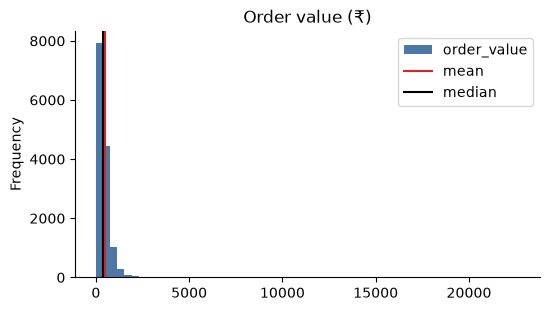

In [39]:
# From here on we work with the cleaned table (duplicates removed).
df = df.drop_duplicates().copy()

aov_mean = df["order_value"].mean()
aov_median = df["order_value"].median()
aov_skew = round(stats.skew(df["order_value"]), 1)

if ready(aov_mean, aov_median):
    print(f"mean = ₹{aov_mean:.0f} | median = ₹{aov_median:.0f} | skew = {aov_skew}")
    df["order_value"].plot.hist(bins=60, color="#4c78a8", title="Order value (₹)")
    plt.axvline(aov_mean, color="#d62728", label="mean"); plt.axvline(aov_median, color="black", label="median")
    plt.legend(); plt.show()

In [40]:
# Where are the ratings missing?
df.groupby("city")["rating"].apply(lambda s: s.isna().mean() * 100).round(1)

city
Bengaluru    21.1
Hyderabad    45.0
Pune         20.6
Name: rating, dtype: float64

**✏️ Your answer (Part 1):**
(a) Which AI insight(s) are affected by what you just found about the *average*, and how should the statement be rewritten?

*Your answer:*Insight 2 is affected because the mean order value is approximately ₹465, while the median is ₹358. The large difference indicates that a few unusually high-value orders are pulling the mean upward. The statement should be rewritten as: "The mean order value is approximately ₹465, while the median is ₹358, indicating a highly right-skewed distribution."
(b) Insight 6 uses ratings. What risk does the missing-rating pattern create?

*Your answer:*Approximately 27.6% of ratings are missing, with Hyderabad having the highest missing-rating percentage of approximately 45%. This can create biased conclusions because the available ratings may not represent all customers. Therefore, the AI should investigate the missing data before making strong conclusions about customer satisfaction.

---
## Part 2 · Defaults shape the story: bin width

The assistant looked at a 1-minute-bin histogram of one store's deliveries and wrote: *"Delivery times are **multimodal**, with three separate peaks."* Look at the same 150 orders with different bin widths.

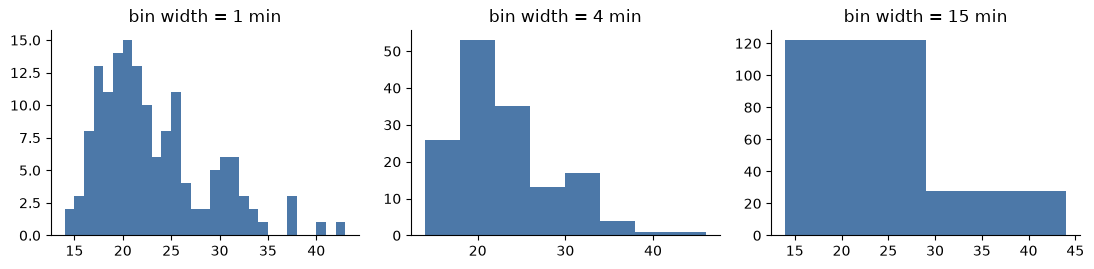

In [41]:
sample = df[df.store_id == "B3"].sample(150, random_state=1)["delivery_minutes"]
fig, axes = plt.subplots(1, 3, figsize=(11, 2.8))
for ax, w in zip(axes, [1, 4, 15]):
    ax.hist(sample, bins=np.arange(sample.min(), sample.max() + w, w), color="#4c78a8")
    ax.set_title(f"bin width = {w} min")
plt.tight_layout(); plt.show()

multimodal_supported = False
best_bin_width = 4

**✏️ Your answer (Part 2):** In one sentence, what should the analyst do before accepting a shape claim from an automated report?

*Your answer:*The analyst should compare the histogram using different bin widths and examine the underlying data before accepting a claim about its distribution.

---
## Part 3 · Trends, correlations and patterns

### 3a · Trend (insight 1)

slope = 56.2 orders/month | Kendall tau = 0.89, p = 0.0002


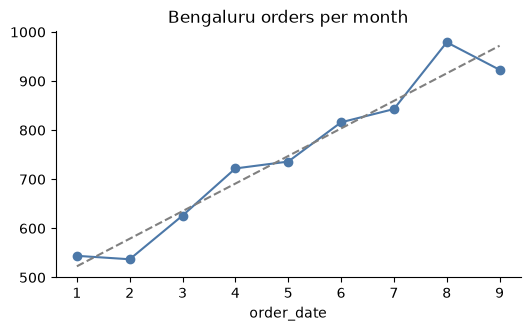

In [42]:
bengaluru = df[df.city == "Bengaluru"]
monthly = bengaluru.groupby(bengaluru["order_date"].dt.month).size()
months = monthly.index.values

slope = np.polyfit(months, monthly.values, 1)[0]
tau, p_trend = stats.kendalltau(months, monthly.values)    # Mann–Kendall-style trend test

if ready(slope):
    print(f"slope = {slope:.1f} orders/month | Kendall tau = {tau:.2f}, p = {p_trend:.4f}")
    ax = monthly.plot(marker="o", color="#4c78a8", title="Bengaluru orders per month")
    ax.plot(months, np.polyval(np.polyfit(months, monthly.values, 1), months), "--", color="grey")
    plt.show()

### 3b · Correlation (insights 6 and 7)

discount~items r = 0.38 | minutes~rating r = -0.316 | hours~rating r = -0.316


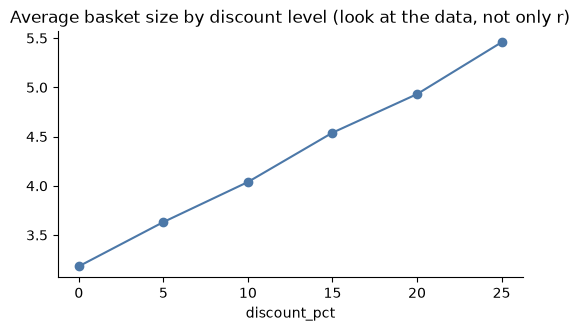

In [43]:
r_disc_items = df["discount_pct"].corr(df["items"])

rated = df.dropna(subset=["rating"]).copy()
rated["delivery_hours"] = rated["delivery_minutes"] / 60
r_minutes = rated["delivery_minutes"].corr(rated["rating"])
r_hours = rated["delivery_hours"].corr(rated["rating"])
r_unchanged = np.isclose(r_minutes, r_hours)

if ready(r_disc_items, r_unchanged):
    print(f"discount~items r = {r_disc_items:.2f} | minutes~rating r = {r_minutes:.3f} | hours~rating r = {r_hours:.3f}")
    df.groupby("discount_pct")["items"].mean().plot(marker="o", color="#4c78a8",
        title="Average basket size by discount level (look at the data, not only r)")
    plt.show()

### 3c · Scanning many pairs

The assistant also scanned **every pair** of the 7 numeric columns below and flags any pair with p < 0.05 as a "finding".

In [44]:
num_cols = ["order_value", "items", "discount_pct", "distance_km", "delivery_minutes", "app_sessions_7d", "loyalty_points"]
n_pairs = len(list(itertools.combinations(num_cols, 2)))
expected_false = n_pairs * 0.05
bonferroni = 0.05 / n_pairs

rows = []
for a, b in itertools.combinations(num_cols, 2):
    r, p = stats.pearsonr(df[a], df[b])
    rows.append((a, b, round(r, 3), p))
scan = pd.DataFrame(rows, columns=["x", "y", "r", "p"]).sort_values("p")

if ready(n_pairs, expected_false, bonferroni):
    print(f"pairs = {n_pairs} | expected false positives = {expected_false:.2f} | Bonferroni threshold = {bonferroni:.4f}")
    flagged = scan[scan["p"] < 0.05].copy()
    flagged["survives_bonferroni"] = flagged["p"] < bonferroni
    display(flagged)

pairs = 21 | expected false positives = 1.05 | Bonferroni threshold = 0.0024


,x,y,r,p,survives_bonferroni
0,order_value,items,0.325,0.000000e+00,True
6,items,discount_pct,0.378,0.000000e+00,True
15,distance_km,delivery_minutes,0.748,0.000000e+00,True
1,order_value,discount_pct,0.066,5.802888e-15,True
14,discount_pct,loyalty_points,-0.022,8.317915e-03,False


**✏️ Your answer (3a–3c):**
(a) Insight 1 rests on 9 monthly points. Is the trend claim reasonable, and what would you show with it?
The overall upward trend is reasonable because Bengaluru orders increased from 544 in January to 923 in September, with an estimated growth of approximately 56 orders per month. However, the growth was not perfectly steady because orders decreased in February and September. I would show a monthly line chart with the trend line.

(b) Insight 7 says discounts and baskets "move together". Does the chart support the wording, and can the AI say discounts *cause* bigger baskets?
The correlation of approximately 0.38 indicates a moderate positive relationship between discounts and the number of items in a basket. The chart supports the statement that they move together, but it does not prove that discounts cause customers to buy more items.

(c) Look at the flagged table. Which pair is most likely a false alarm, and what are **two** reasons you say so?
The relationship between discount_pct and loyalty_points is most likely a false alarm. Its correlation is extremely weak at approximately -0.022, and its p-value does not pass the Bonferroni-corrected threshold. This could be a statistically significant result caused by testing many pairs rather than a meaningful relationship.



### 3d · Patterns: grouping the stores

The assistant ran **PCA + k-means (k = 3)** on store-level features and proposed three store "segments".

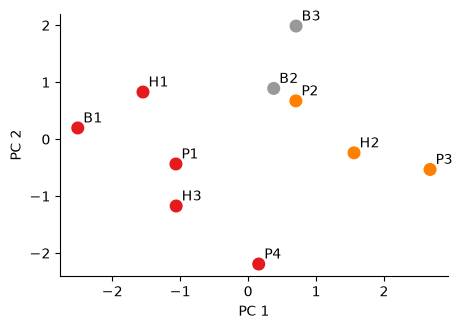

,segment,orders_per_active_day,on_time,suburban_share
store_id,,,,
B1,0,8.29,0.92,0.35
H1,0,4.99,0.91,0.35
P1,0,4.76,0.90,0.37
H3,0,4.30,0.91,0.39
P4,0,4.34,0.88,0.41
H2,1,5.24,0.89,0.45
P3,1,5.25,0.88,0.48
P2,1,4.39,0.91,0.42
B2,2,8.90,0.90,0.45


In [45]:
d = df.assign(month=df["order_date"].dt.month)
store = df.groupby("store_id").agg(
    orders=("order_id", "count"),
    median_value=("order_value", "median"),
    on_time=("on_time", "mean"),
    suburban_share=("zone", lambda s: (s == "Suburban").mean()),
    avg_discount=("discount_pct", "mean"),
    active_days=("order_date", "nunique"),
)
store["orders_per_active_day"] = store["orders"] / store["active_days"]
feats = store.drop(columns=["orders", "active_days"])

Z = StandardScaler().fit_transform(feats)
pcs = PCA(n_components=2).fit_transform(Z)
store["segment"] = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(Z)

fig, ax = plt.subplots(figsize=(5, 3.4))
ax.scatter(pcs[:, 0], pcs[:, 1], c=store["segment"], cmap="Set1", s=70)
for sid, (x, y) in zip(store.index, pcs):
    ax.annotate(sid, (x, y), xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); plt.show()
store[["segment", "orders_per_active_day", "on_time", "suburban_share"]].round(2).sort_values("segment")

**✏️ Your answer (3d):** The AI says these are three meaningful store "types". With only 10 stores, what is one reason a human should hesitate, and what would you check before naming the segments?

*Your answer:*With only 10 stores, the clustering results may be unstable and may not represent meaningful business categories. Before naming the segments, I would examine the characteristics of each cluster, test whether the groups remain similar with different clustering settings, and discuss whether the differences make sense operationally.

---
## Part 4 · From an observation to hypotheses (insight 4)

**Observation:** Hyderabad orders fell sharply in September. The AI jumped straight to "service got worse". A better assistant would list *competing* hypotheses and the evidence that separates them:

| | Hypothesis | Test |
|---|---|---|
| A | Delivery service got worse | on-time % in Aug vs Sep |
| B | A data problem: some store has missing rows | rows per store per week |
| C | Discounts were cut in September | mean discount, Aug vs Sep |
| D | Customers switched to a competitor | needs competitor/customer data we do not have |

In [46]:
hyd = df[df.city == "Hyderabad"]
hyd_month = hyd.groupby(hyd["order_date"].dt.month).size()
change_pct = ((hyd_month.loc[9] - hyd_month.loc[8]) / hyd_month.loc[8]) * 100
first_test = "B"

if ready(change_pct, first_test):
    print(f"Hyderabad Aug -> Sep: {change_pct:.1f}% | cheapest test first: {first_test}")

Hyderabad Aug -> Sep: -28.4% | cheapest test first: B


In [47]:
# Run the tests for hypotheses B and A
weekly = hyd.groupby([pd.Grouper(key="order_date", freq="W"), "store_id"]).size().unstack(fill_value=0)
display(weekly.tail(9))

ontime = hyd.groupby(hyd["order_date"].dt.month)["on_time"].mean() * 100
ontime_change_pts = ontime.loc[9] - ontime.loc[8]
culprit_store = "H2"

if ready(ontime_change_pts, culprit_store):
    print(f"on-time change Aug->Sep = {ontime_change_pts:+.1f} points | store with the gap: {culprit_store}")

store_id,H1,H2,H3
order_date,,,
2026-08-09,33,36,39
2026-08-16,41,32,17
2026-08-23,39,35,36
2026-08-30,46,39,28
2026-09-06,37,28,36
2026-09-13,33,0,21
2026-09-20,43,0,38
2026-09-27,38,11,31
2026-10-04,17,18,19


on-time change Aug->Sep = -0.3 points | store with the gap: H2


**✏️ Your answer (Part 4):** In two sentences, which hypotheses did the data support or rule out? Write the corrected version of insight 4 that you would be willing to show Meera.

*Your answer:*
(a) Hypothesis evaluation:

The data supports hypothesis B because store H2 has missing weekly order records in September. Hypothesis A is not supported because the on-time delivery rate decreased by only approximately 0.3 percentage points, while hypothesis C is not supported because average discounts remained nearly unchanged. Hypothesis D cannot be tested using the available dataset because competitor and customer-switching information is unavailable.

(b) Corrected Insight 4:

Hyderabad orders decreased by approximately 28.4% in September compared with August. Missing weekly records from store H2 suggest a possible data-quality issue, so the decline cannot be confidently attributed to worsening delivery service.

---
## Part 5 · Validate and correct two more claims

### 5a · "Pune orders more than doubled" (insight 3)

In [48]:
pune = df[df.city == "Pune"].copy()
pune["quarter"] = pune["order_date"].dt.quarter
by_store = pune.pivot_table(index="store_id", columns="quarter", values="order_id", aggfunc="count", fill_value=0)
display(by_store)

old = by_store.loc[["P1", "P2"]]                  # the stores that were open in both Q2 and Q3
like_for_like_pct = ((old[3].sum() - old[2].sum()) / old[2].sum()) * 100

if ready(like_for_like_pct):
    print(f"like-for-like growth = {like_for_like_pct:+.1f}%")

quarter,1,2,3
store_id,,,
P1,423,423,443
P2,388,380,421
P3,0,0,483
P4,0,0,399


like-for-like growth = +7.6%


Now draw the *corrected* message. The chart below already greys the context and highlights the new stores (Knaflic: grey the context, one accent colour, title with the takeaway). **Write the title.**

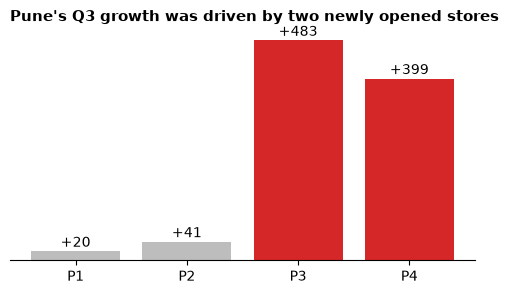

In [49]:
title = "Pune's Q3 growth was driven by two newly opened stores"

change = by_store[3] - by_store[2]
colors = ["#bdbdbd" if s in ("P1", "P2") else "#d62728" for s in by_store.index]
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(change.index, change.values, color=colors)
for x, v in zip(change.index, change.values):
    ax.text(x, v + 10, f"{v:+d}", ha="center")
ax.set_yticks([]); ax.spines["left"].set_visible(False)
ax.set_title(title if title else "(write a takeaway title)", loc="left", fontsize=11, fontweight="bold")
plt.show()

### 5b · "Partner B is more punctual, send everything to B" (insight 5)

In [50]:
overall = df.groupby("delivery_partner")["on_time"].mean().mul(100).round(1)
mix = (pd.crosstab(df["delivery_partner"], df["zone"], normalize="index") * 100).round(0)
print("Overall on-time %:\n", overall, "\n\nShare of each partner's orders by zone (%):\n", mix)
by_zone = (df.groupby(["zone", "delivery_partner"])["on_time"].mean() * 100).unstack().round(1)
better_in_every_zone = "Partner A"
phenomenon = "Simpson's paradox"

if ready(by_zone, better_in_every_zone, phenomenon):
    display(by_zone)
    print(f"Better inside every zone: {better_in_every_zone} | effect: {phenomenon}")

Overall on-time %:
 delivery_partner
Partner A    87.1
Partner B    93.0
Name: on_time, dtype: float64 

Share of each partner's orders by zone (%):
 zone              Suburban  Urban
delivery_partner                 
Partner A             67.0   33.0
Partner B             16.0   84.0


delivery_partner,Partner A,Partner B
zone,,
Suburban,81.4,72.0
Urban,98.8,96.9


Better inside every zone: Partner A | effect: Simpson's paradox


**✏️ Your answer (Part 5):** (a) Rewrite insight 3 so it is honest. 
Pune's total orders increased by approximately 117% from Q2 to Q3, mainly because two new stores, P3 and P4, started operating. However, the existing stores P1 and P2 recorded only approximately 7.6% like-for-like growth, so the expansion should not be described as a huge success based only on total orders.

(b) Explain in plain language why Partner B *looks* better overall, and what question a careful human asks before accepting a comparison like insight 5.
Partner B looks better overall because it handles a much larger proportion of urban orders, where delivery punctuality is generally higher. When comparing partners within each zone separately, Partner A performs better in both urban and suburban areas. A careful analyst should ask whether both partners handle a similar mix of urban and suburban orders before accepting the overall comparison. This is an example of Simpson's paradox.



---
## Part 6 · Triage the whole report

For each AI insight decide: **Accept** (correct as stated), **Correct** (the finding is useful but the wording or number must change) or **Reject** (not supported). Then measure the AI.

In [51]:
decisions = {
    1: "Correct",
    2: "Accept",
    3: "Correct",
    4: "Correct",
    5: "Correct",
    6: "Accept",
    7: "Accept",
    8: "Accept",
    9: "Reject",
}
analysts_true_insights = 7    # true insights an expert team found in this data (given)

accepted = sum(v == "Accept" for v in decisions.values())
if all(v in ("Accept", "Correct", "Reject") for v in decisions.values()):
    accepted = sum(v == "Accept" for v in decisions.values())
    precision = accepted / len(decisions)
    recall = accepted / analysts_true_insights
    f1 = 2 * precision * recall / (precision + recall) if accepted else 0
    print(f"Accepted as stated: {accepted}/{len(decisions)} | precision = {precision:.2f} | recall = {recall:.2f} | F1 = {f1:.2f}")
    print(f"Review effort spent on insights that were not fully correct: {(len(decisions) - accepted) / len(decisions):.0%}")
else:
    print("⚠ Fill in all nine decisions with 'Accept', 'Correct' or 'Reject'.")

Accepted as stated: 4/9 | precision = 0.44 | recall = 0.57 | F1 = 0.50
Review effort spent on insights that were not fully correct: 56%


**✏️ Your answer (Part 6):** Using precision and recall, would you describe this AI as an *assistant* or a *replacement* for the analyst? Justify in two sentences.

*Your answer:*
I would describe this AI as an assistant rather than a replacement because some of its findings require correction, additional investigation or rejection. Precision and recall help measure its performance, but a human analyst is still needed to validate the results, identify misleading conclusions and make final decisions.

---
## Part 7 · Communicating, steering and validating

### 7a · Three kinds of reading
Each insight reads the data at a different level: **`data`** (restates what is plotted), **`between`** (relationships or patterns) or **`beyond`** (predictions and causal explanations; the risk zone).

In [52]:
levels = {
    2: "data",
    6: "between",
    9: "beyond",
}
print(levels)

{2: 'data', 6: 'between', 9: 'beyond'}


### 7b · Steering the assistant (interactive refinement)
Match each thing Meera types to the kind of feedback it is: **Reject**, **Constrain**, **Steer**, **Adjust** or **Pin**.

In [53]:
user_actions = {
    '"Never use pie charts in this report"': "Constrain",
    '"Use 5-minute bins for delivery time"': "Adjust",
    '"Focus on on-time rate by city"': "Steer",
    '"Keep the like-for-like Pune chart on the dashboard"': "Pin",
    '"Not this chart again"': "Reject",
}
user_actions

{'"Never use pie charts in this report"': 'Constrain',
 '"Use 5-minute bins for delivery time"': 'Adjust',
 '"Focus on on-time rate by city"': 'Steer',
 '"Keep the like-for-like Pune chart on the dashboard"': 'Pin',
 '"Not this chart again"': 'Reject'}

### 7c · Which validation threat?
Meera now says: *"My real worry is why **repeat customers** are leaving. The AI answered a different question: how orders changed."* The AI's numbers were all computed correctly.

In [54]:
threat = "wrong problem"
threat

'wrong problem'

**✏️ Your answer (Part 7):** Rewrite insight 2 *and* insight 4 as statements you would be comfortable presenting. Each rewrite should use the right measure or the right scope, avoid causal language the data cannot support, and be specific (no "interesting variation").

*Your answer:*
Insight 2: The mean order value is approximately ₹465, while the median is ₹358, indicating a highly right-skewed distribution with some unusually high-value orders.

Insight 4: Hyderabad orders decreased by approximately 28.4% in September compared with August, while the on-time delivery rate decreased by only 0.3 percentage points. Missing weekly order records from store H2 suggest a possible data issue that requires investigation.

---
## Reflection

Answer in 2–4 sentences each. There are no right-or-wrong answers here; we are looking for honest thinking about *your own* process.

**1. Automation bias.** Before you checked anything, which AI insight did you find most convincing? What made it convincing (the number, the tone, the chart, the confident wording), and would you have caught the problem without the checks?

*Your reflection:*
I found the Hyderabad order decline (Insight 4) most convincing because the AI presented a clear percentage decrease with confident wording. Initially, I would have assumed that the store's performance had declined. However, after checking the data, I discovered missing records from store H2, which suggested a possible data problem rather than an actual business decline. Without checking the data, I might have accepted the AI's explanation.


**2. Choosing the level of automation.** For FreshKart, name one task where you would let the AI work with little supervision and one where you would insist on a human check. What did you use to decide (stakes, reversibility, how visible errors are)?

*Your reflection:*
I would allow AI to perform basic tasks such as calculating averages, identifying missing values and generating charts with little supervision. However, I would insist on human verification before accepting business recommendations or conclusions that could affect important decisions. I made this distinction based on the impact of incorrect results and the possibility of correcting mistakes.

**3. Making trust cheaper.** Pick one problem you found (e.g. the Hyderabad gap, the missing ratings, or Partner B). What should the AI tool have *shown* (code, sample size, data gaps, uncertainty) so you could verify it faster, and what control would you want (edit, undo, switch off)?

*Your reflection:*
I would choose the Hyderabad missing-data problem. The AI should have displayed weekly order counts for each store along with clear warnings about missing records, making it easier to identify the issue. I would also want the option to edit the analysis, undo changes and inspect the underlying data before accepting its conclusions.

**4. Responsibility.** If Meera presents the corrected report and one number is still wrong, who is accountable, the AI, the tool's vendor, you or Meera? What would you do differently next time to carry that responsibility well?

*Your reflection:*
Meera and the analyst responsible for verifying the report should take responsibility for the final information presented, rather than blaming the AI alone. The AI is only a tool and its outputs must be checked before being used for business decisions. Next time, I would independently verify important calculations, document the validation steps and clearly mention any remaining uncertainties.